# MEMAR over DRACH motives only, with fixed imbalance to 10%-90% A from GLORI-seq experiments in HEK293T cells

### Import packages

In [1]:
#Packages needed for the notebook
using CSV 
using Serialization 
using Revise 
using LinearAlgebra 
using ReverseDiff 
using Random 
using PyPlot 
using NaNStatistics 
using Statistics 

### Including Files

In [2]:
function correct_path(splitted_path, String)
    """Function to retrieve files in a given path.
    It takes as input:
        1) splitted path: the current path split by each separator
        2) String: the path to reach the wanted file 
    The function returns:
        1) the correct complete path to reach the file
    """
    S="" #String initialization
    for i in 1:(length(splitted_path)-1)
        #Constructing the path with the correct separator and removing the last term
        S=S*splitted_path[i]*"/" 
    end
    #Final Output
    return S*String 
end

correct_path (generic function with 1 method)

In [3]:
#Including files with the functions
includet(correct_path(split(pwd(), '/'), "Functions/Variables and Structures.jl")) #For constant quantities or structures to save data
includet(correct_path(split(pwd(), '/'), "Functions/Inference.jl")) #For Training
includet(correct_path(split(pwd(), '/'), "Functions/Model Strategies and Testing.jl")) #For scoring testing datasets
includet(correct_path(split(pwd(), '/'), "Functions/Performance Indicator.jl")) #To compute performance over test datasets

### Datasets

In [4]:
#Importing, training, test and prior datasets
train=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Train_GLORI.bin")) 
test=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Test1_GLORI.bin")) 
prior_HEK=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Prior_GLORI.bin")); 

In [5]:
#Importing models trained on GLORI HEK293T
M5=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_met.bin")) # p(s̄|m)
M6=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_not_met.bin")); # p(s̄|m̄)

In [6]:
#Saving all the gene labels for the three datasets
gene_train=keys(train);
gene_test=keys(test);
gene_prior=keys(prior_HEK);

### Distibution of motives (train-set):

In [7]:
#Computing distribution of m6A and A over transcripts
bin=collect(0:0.001:1);
avarege_window=20
x_met, y_met=avarege_distribution(train, gene_train, avarege_window, bin; label=1) #d(x(s̄_T |m))
x_not, y_not=avarege_distribution(train, gene_train, avarege_window, bin, label=0); #d(x(s̄_T |m̄))

### Test:

In [8]:
#To test genes I only keep those transcripts for which a proxy of the methylation abundancy is knwon
common_genes=intersect(vcat(gene_prior...),vcat(gene_test...)) # T̃ ∩ T 
genes_not=filtering_non_nucelotides(test)
#Removing genes if non canonical nucleotide letters are present
common_genes=setdiff(common_genes, genes_not); # T̃ ∩ T \ T_n 

The gene PLCL2 contain a (some) non-nucleotide(s) character(s) at position(s) [3518] corresponding to the chacracter(s): W 


### Mapping:

In [9]:
#Mapping all coding transcripts into a sequnence of 33.3̄% 5'-UTR, 33.3̄% CDS, 33.3̄% 3'-UTR
MAP=mapping_position(test, common_genes);

### Analysis only over DRACH motifs


In [10]:
#Definition of a Dictionary containing all DRACH motives
Dict_DRACH=Dict()
[Dict_DRACH[a]=[]  for a in DRACH];
#Creating all test sets over coding transcripts
test_met, ratio_test , gene_test_met , test_not , gene_test_not =crete_set_all(test, (keys(MAP)));

### Baseline DRACH model 

In [11]:
#Creating datasets for methylated DRACH and non-methylated DRACH motifs
test_met_D=filter_DRACH(test_met)
test_not_D=shuffle!(filter_DRACH(test_not))[1:9*length(test_met_D)];

$$p_{BaselineDRACH}(m|\vec{s})=\begin{cases} 1 \ \ \ \ \ if \ \vec{s}\in DRACH \\0 \ \ \ \ \  otherwise \end{cases}$$

In [12]:
#Numerical translation of the previous equation
N_met_a=[null_model(test_met_D[i]) for i in 1:length(test_met_D)];
N_not_a=[null_model(test_not_D[i]) for i in 1:length(test_not_D)];
#Computing the PCR point and the F1 score
x,y=sum(N_met_a)/length(N_met_a) ,sum(N_met_a)/(sum(N_met_a)+sum(N_not_a)) 
F1=2 .* (y.*x)./(y.+x);
#ROC point
x_R,y_R=sum(N_not_a)/length(N_not_a) , sum(N_met_a)/length(N_met_a);

### 1. MEMAR-C: Constant prior

In [13]:
#Constant prior definition following the previous equation
Ava=[] 
[push!(Ava, train[a].perc_met) for a in gene_train];
Ava=mean(Ava)
constant_prior=deepcopy(test)
[constant_prior[a].perc_met=Ava for a in keys(test)];

In [14]:
score_met_ps,score_not_met_ps,_=score_ps_ds_pm_DRACH(M5, M6, test, keys(MAP), constant_prior)

(Any[Any[0.2745705111723003, 0.25090213966349334, 0.1974817546243163, 0.04949597649732872], Any[0.20544373735755916], Any[0.32170134703050096, 0.1309860003343313, 0.2743800284346555, 0.1939716294142271, 0.06984113836593894, 0.0743441618182109, 0.29060031633779765, 0.3346314040085741, 0.1295054905018457, 0.2206974935852467, 0.06327624827678813, 0.030283689478514335, 0.42369507254178057, 0.10938993702892211, 0.2961209078941224, 0.5962980450093881, 0.40248928775365567, 0.5539446597199333], Any[0.2262029200609397, 0.2702990894127334, 0.14736528886355552, 0.3268734475838414, 0.1353592482004539, 0.25596055200276263, 0.13336212918215676, 0.20374564815984786, 0.506817269282509, 0.1534691682798441, 0.2001385717793308], Any[0.5062118682051703, 0.3596121532170852], Any[0.16909974742004438, 0.10647411014814824, 0.575440829995628], Any[0.26715373299114914, 0.6618623806988002, 0.4552027318535536, 0.49490118893316953, 0.17280224679607195, 0.4875290071185015, 0.28165011598386025, 0.21070475449460233, 

### 2. MEMAR-XC: Modulated distance with constant prior
$p(m|\vec{s})\propto p(\vec{s}|m)\cdot d(x_T(\vec{s})|m) \cdot p_0(m)$

In [15]:
score_met_ps_ds,score_not_met_ps_ds=score_ps_ds_pm_DRACH(M5, M6, test, keys(MAP), constant_prior; verb=true, map=MAP,d_met=[x_met, y_met], d_not=[x_not, y_not])

(Any[Any[0.4414283582868467, 0.3127145050021377, 0.1190259406096522, 0.0264530372204996], Any[0.22813621571129755], Any[0.3507608760914169, 0.14405312921772676, 0.2938120752655908, 0.21574101030117895, 0.07746167101021925, 0.0822848264226595, 0.3253281042983532, 0.6250398160405926, 0.32638538621808816, 0.4616783534230776, 0.1660670749676901, 0.07799065368804309, 0.45933027745995547, 0.11845372275876428, 0.3151812997694182, 0.616806383347132, 0.4006760362008321, 0.44008305579199386], Any[0.24701976636418796, 0.5505957913985456, 0.2749578380199701, 0.292439484914302, 0.07414148169865983, 0.15023752445757582, 0.07675326186161124, 0.12144746655527601, 0.33105658491946904, 0.0770210820649154, 0.10349991525415261], Any[0.5432616353849862, 0.3873870785186232], Any[0.2595850870700967, 0.16223304549343776, 0.6302684372375711], Any[0.16815788246790647, 0.5157094715075278, 0.35151385719771205, 0.5315010616294614, 0.19472933129409695, 0.5236864132579937, 0.29887683923756003, 0.2324571828264075, 0.

###  3. MEMAR-T: Transcript-dependent Prior
$p(m|\vec{s})\propto p(\vec{s}|m) \cdot p_0^T(m) \ \ \ where \ \ \ p_0^{T_j}(m)=\frac{\langle p_0^{T'}(m)\rangle_{T'}}{\langle p_0^{\tilde{T}}(m)\rangle_{\tilde{T}}}p_0^{\tilde{T}_j}(m) $

In [16]:
# Transcript-dependent prior following the above equation
P=[]
[push!(P, prior_HEK[a].perc_met) for a in keys(prior_HEK)]
[prior_HEK[a].perc_met=Ava/mean(P).*prior_HEK[a].perc_met for a in keys(prior_HEK)];

In [17]:
score_met_ps_pm,score_not_met_ps_pm=score_ps_ds_pm_DRACH(M5, M6, test, keys(MAP), prior_HEK)

(Any[Any[0.07133416502119341, 0.06364794738032098, 0.04756493061862451, 0.010457546288766016], Any[0.023232065168918903], Any[0.3148739997269654, 0.12744565166416502, 0.2681599286871792, 0.1890993235484385, 0.06782445515886697, 0.07220754632901165, 0.2841565047590378, 0.3276622046411365, 0.12599935576862806, 0.21533321483411705, 0.061436607617536075, 0.029373168945495673, 0.4160307806408819, 0.10636185428522602, 0.2896046562778674, 0.5887009107667328, 0.3949457105840644, 0.546157114546926], Any[0.323882369132678, 0.3777251320446662, 0.220711270979726, 0.44312972522943384, 0.20416047342638763, 0.360503334672768, 0.20138467673557442, 0.295430000572401, 0.6274192731084993, 0.22903707095797335, 0.29079254103926655], Any[0.6049800749466475, 0.45620319599675485], Any[0.26057802313189604, 0.17104787736163857, 0.7012253255050354], Any[0.37050517760401147, 0.7596325704958207, 0.5742935399891674, 0.6126975518431126, 0.25221483852726717, 0.6056747735458307, 0.3876432192593813, 0.30119347159527377

### 4. MEMAR-XT: Modulated distant with non-uniform prior
$p(m|\vec{s}) \propto p(\vec{s}|m) d(x_T(\vec{s})|m)\cdot p_0^T(m)$

In [18]:
score_met_ps_ds_pm,score_not_met_ps_ds_pm=score_ps_ds_pm_DRACH(M5, M6, test, keys(MAP), prior_HEK; verb=true, map=MAP,d_met=[x_met, y_met], d_not=[x_not, y_not]);

#### Statistics

In [19]:
println("Number of Genes: $(length(score_met_ps_ds_pm))")
println("Number of m6A: $(length(vcat(score_met_ps_ds_pm...)))")
println("Number of A: $(length(vcat(score_not_met_ps_ds_pm...)))")

Number of Genes: 1398
Number of m6A: 9170
Number of A: 114508


### Precision Recall Curve

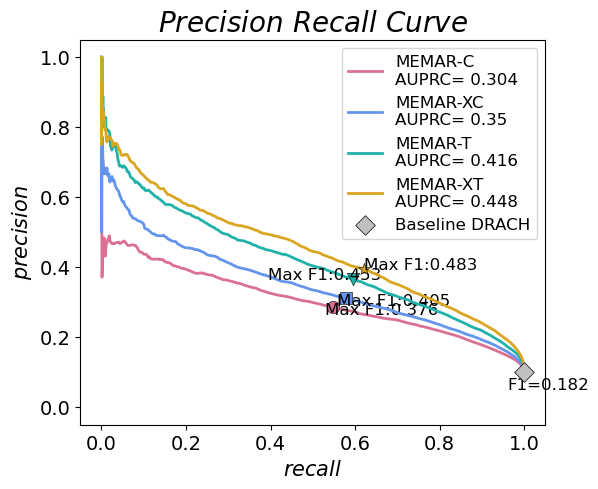

In [20]:
close("all")
figure(figsize=(6, 5))
L1=shuffle!(vcat(1:length(vcat(score_not_met_ps...))))[1:9*length(vcat(score_met_ps...))]
_,tr1=plot_PR_score(vcat(score_met_ps...), vcat(score_not_met_ps...)[L1],  "palevioletred","MEMAR-C"; xx=-0.02, pas=0.005,ls="-",mark="o")
_,tr2=plot_PR_score(vcat(score_met_ps_ds...), vcat(score_not_met_ps_ds...)[L1],  "cornflowerblue","MEMAR-XC"; xx=-0.02,pas=0.005, ls="-",mark="s")
_,tr3=plot_PR_score(vcat(score_met_ps_pm...), vcat(score_not_met_ps_pm...)[L1],  "lightseagreen","MEMAR-T"; xx=-0.2,yy=0, pas=0.005,ls="-",mark="v")
_,tr4=plot_PR_score(vcat(score_met_ps_ds_pm...), vcat(score_not_met_ps_ds_pm...)[L1],  "goldenrod","MEMAR-XT"; xx=0.0,pas=0.005, ls="-",mark="*")
scatter(x, y, marker="D", color="silver", edgecolor="black", linewidth=0.5, label="Baseline DRACH", zorder=4, s=100)
text(x-.04, y-0.05, "F1=$(round(F1, digits=3))", fontsize=12)
title(L"Precision \ Recall \ Curve", size=20)
xlabel(L"recall", size=15)
ylabel(L"precision", size=15)
xlim(-0.05, 1.05)
ylim(-0.05, 1.05)
xticks(fontsize=14)
yticks(fontsize=14)
legend(fontsize=12)
gcf()

### Receveir Operating Curve

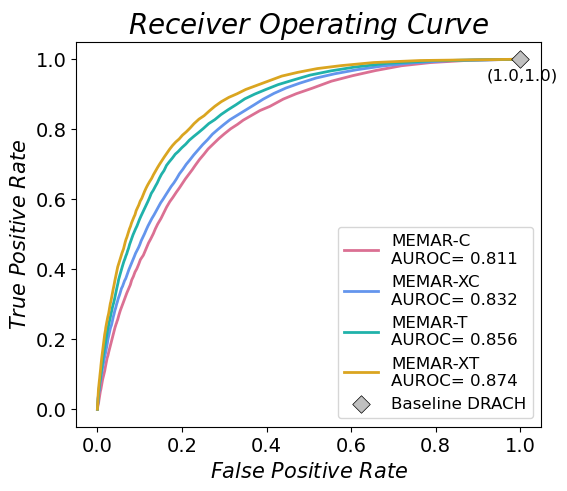

In [30]:
close("all")
close("all")
figure(figsize=(6, 5))
_=plot_ROC_score(vcat(score_met_ps...), vcat(score_not_met_ps...)[L1],  "palevioletred","MEMAR-C"; xx=-0.02, pas=0.005,ls="-")
_=plot_ROC_score(vcat(score_met_ps_ds...), vcat(score_not_met_ps_ds...)[L1],  "cornflowerblue","MEMAR-XC"; xx=-0.02,pas=0.005, ls="-")
_=plot_ROC_score(vcat(score_met_ps_pm...), vcat(score_not_met_ps_pm...)[L1],  "lightseagreen","MEMAR-T"; xx=0, pas=0.005,ls="-")
_=plot_ROC_score(vcat(score_met_ps_ds_pm...), vcat(score_not_met_ps_ds_pm...)[L1],  "goldenrod","MEMAR-XT"; xx=0.02,pas=0.005, ls="-")
scatter(x_R, y_R, marker="D", color="silver", edgecolor="black", linewidth=0.5, label="Baseline DRACH", zorder=4, s=80)
text(x_R-0.08, y_R-0.06, "($(round(x_R, digits=3)),$(round(y_R, digits=3)))",fontsize=12)
title(L"Receiver \ Operating \ Curve", size=20)

xlabel(L"False \ Positive \ Rate", size=15)
ylabel(L"True \ Positive \ Rate", size=15)
xlim(-0.05, 1.05)
ylim(-0.05, 1.05)
xticks(fontsize=14)
yticks(fontsize=14)
legend(fontsize=12)
gcf()

### Distance distribution

Computing the predicted distirbution of DRACH methylated motifs. Sites, filtered only over DRACH, with higher or equal probability to the treshold for each MEMAR class are retained and projected into a metagene profile of 1/3 5'-UTR,  1/3 CDS and 1/3 3'-UTR. 

#### MEMAR-C

In [20]:
dist_met_pred_ps=[]
for label in keys(MAP)
    S=score_genome_complete(M5, M6, Ava/100, test[label].sequence, 8; verbose=false)
    v=intersect(findall(x->x>=tr1, S), mask_DRACH(test[label].sequence, Dict_DRACH))
    push!(dist_met_pred_ps, MAP[label][v]) 
end

#### MEMAR-XC

In [21]:
dist_met_pred_ps_ds=[]
for label in keys(MAP)
    S=score_genome_complete(M5, M6, Ava/100, test[label].sequence, 8;  verbose=true, Mapping=MAP, dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=label)
    v=intersect(findall(x->x>=tr2, S), mask_DRACH(test[label].sequence, Dict_DRACH))
    push!(dist_met_pred_ps_ds, MAP[label][v]) 
end

#### MEMAR-T

In [22]:
dist_met_pred_ps_pm=[]
for label in keys(MAP)
    S=score_genome_complete(M5, M6, prior_HEK[label].perc_met/100, test[label].sequence, 8; verbose=false)
    v=intersect(findall(x->x>=tr3, S), mask_DRACH(test[label].sequence, Dict_DRACH))
    push!(dist_met_pred_ps_pm, MAP[label][v]) 
end

#### MEMAR-XT

In [31]:
dist_met_pred_ps_ds_pm=[]
for label in keys(MAP)
    S=score_genome_complete(M5, M6, prior_HEK[label].perc_met/100, test[label].sequence, 8;  verbose=true, Mapping=MAP, dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=label)
    v=intersect(findall(x->x>=tr4, S), mask_DRACH(test[label].sequence, Dict_DRACH))
    push!(dist_met_pred_ps_ds_pm, MAP[label][v]) 
end

#### Baseline DRACH model

In [32]:
dist_DRACH=[]
for label in keys(MAP)
    temp=vcat([findall(a, test[label].sequence) for a in DRACH]...)
    pos=[temp[i][3] for i in 1:length(temp)]
    push!(dist_DRACH, MAP[label][sort(pos)]) 
end

In [33]:
#Computing the same dsitribution form experimental methylated sites
x_met_ref, y_met_ref=avarege_distribution_DRACH(test, gene_test, avarege_window, bin;label=1)

([0.0, 0.001, 0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008, 0.009  …  0.99, 0.991, 0.992, 0.993, 0.994, 0.995, 0.996, 0.997, 0.998, 0.999], [0.024037305898754868, 0.02203419707385863, 0.020339258837407965, 0.018886454634735966, 0.03525471531817382, 0.033051295610787956, 0.03888387718916229, 0.04406839414771728, 0.04174900498204795, 0.03966155473294555  …  0.27102062400846083, 0.24353586239527938, 0.22034197073858608, 0.21774971225930861, 0.1900449497620305, 0.158646218931782, 0.16053486439525558, 0.1525444412805596, 0.15423937951701028, 0.12018652949377423])

In [34]:
#Computing the density distirbution in the metagene profile
yy_1, xx_1=hist(vcat(dist_met_pred_ps...), histtype="step" ,bins=bin, density=true, color="palevioletred",alpha=0.4);
yy_2, xx_2=hist(vcat(dist_met_pred_ps_ds...), histtype="step" ,bins=bin, density=true, color="yellowgreen",alpha=0.4);
yy_3, xx_3=hist(vcat(dist_met_pred_ps_pm...), histtype="step" ,bins=bin, density=true, color="lightseagreen",alpha=0.4);
yy_4, xx_4=hist(vcat(dist_met_pred_ps_ds_pm...), histtype="step" ,bins=bin, density=true, color="goldenrod",alpha=0.4);
yy_D, xx_D=hist(vcat(dist_DRACH...), histtype="step" ,bins=bin, density=true, color="lightgrey",alpha=0.4);

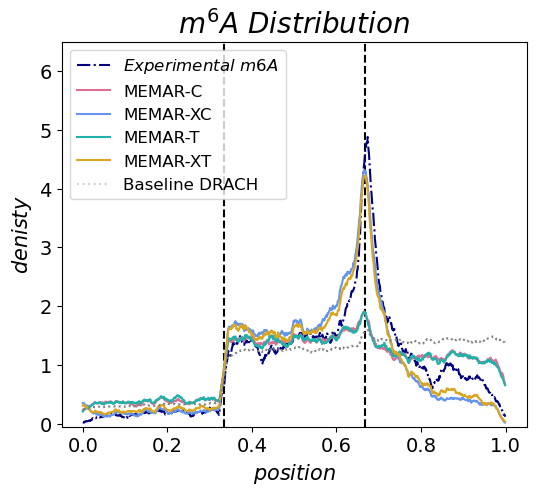

In [35]:
close("all")
figure(figsize=(6, 5))
#plotting each results:
plot(x_met_ref, y_met_ref, color="navy", ls="-.",label=L"Experimental \ m6A ")
plot(xx_1[1:end-1], movmean(yy_1, 20), color="palevioletred")
plot(xx_2[1:end-1], movmean(yy_2, 20), color="cornflowerblue")
plot(xx_3[1:end-1], movmean(yy_3, 20), color="lightseagreen")
plot(xx_4[1:end-1], movmean(yy_4, 20), color="goldenrod")
plot(xx_D[1:end-1], movmean(yy_D, 20), color="grey", ls=":")
axvline(x=1/3, color="black", linestyle="--", zorder=1)
axvline(x=2/3, color="black", linestyle="--", zorder=1)
#Legend
plot(1, 1, label="MEMAR-C",color="palevioletred")
plot(1, 1, label="MEMAR-XC",color="cornflowerblue")
plot(1, 1, label="MEMAR-T",color="lightseagreen")
plot(1, 1, label="MEMAR-XT",color="goldenrod")
plot(1, 1, label="Baseline DRACH ",ls=":",color="lightgrey")

title(L"m^6A \ Distribution", size=20)
ylabel(L"denisty", size=15)
xlabel(L"position", size=15)
ylim(-0.05, 6.5)
xticks(fontsize=14)
yticks(fontsize=14)
legend(fontsize=12)
gcf()